
# Graph WaveNet for Traffic Congestion Prediction

## Project Overview

*   This project implements a Graph WaveNet-based spatiotemporal forecasting model using the MMTD (Madrid Metropolitan Traffic Dataset).
*  The objective is to predict traffic congestion across multiple road sensors using historical traffic observations and additional features.
*  The model uses the previous 12 timestamps (3 hours of historical observations, with a 15-minute sampling interval) to predict congestion at the next timestamp for all selected sensors.
* We use Graph WaveNet, a spatiotemporal GNN that learns patterns across time, road sensors and other relationships between nodes.
* The trained model is evaluated using Mean Absolute Error (MAE).
* Its performance is compared against a persistence baseline, which predicts that the next congestion value will be equal to the most recently observed value.

### Dataset Configuration

| Parameter | Value |
|---|---|
| Dataset | MMTD |
| Location | Madrid, Spain |
| Number of sensors | 2780 |
| Number of Timestamps per sensor | 2978 |
| Input sequence length | 12 timestamps |
| Sampling interval | 15 minutes |
| Input features | 49 |
| Prediction target | Congestion level |
| Prediction horizon | 15 minutes ahead |

# Environment Setup

Get the dataset

In [ ]:
!git clone https://github.com/qishenzhou/MMTD.git

Download `distance_matrix.h5`, `road_info.h5` and `fixed_sensor_data.h5` and put them in `MMTD/data`

In [ ]:
!python -m pip install -r requirements.txt

In [ ]:
!python -m examples.load_fixed_sensor --data-root ./data

Get the GNN model

In [ ]:
!git clone https://github.com/nnzhan/Graph-WaveNet.git

In [ ]:
%cd Graph-WaveNet

In [ ]:
!pip install torch numpy pandas h5py scipy scikit-learn

# Imports

In [34]:
from pathlib import Path
import sys
import os
import h5py
import json
import shutil
import requests
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader
from model import gwnet
import torch.nn.functional
import torch.optim as optim

# Configuration

Change all parameters here if needed

In [15]:
# Dataset
TIMESTAMPS = 2976
MAX_NODES = 2780
SEQ_LEN = 12
TARGET_FEATURE = 2

# Graph
TOP_K = 15
SIGMA_KM = 1.5

# Training
BATCH_SIZE = 4
EPOCHS = 30
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

# Model
HORIZON_IDX = -1

# Output dir
CHECKPOINT_DIR = Path("checkpoints")
RESULTS_DIR = Path("results")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Maximum nodes:", MAX_NODES)
print("Input sequence length:", SEQ_LEN)
print("Batch size:", BATCH_SIZE)
print("Training epochs:", EPOCHS)

Maximum nodes: 2780
Input sequence length: 12
Batch size: 4
Training epochs: 30


# Prepare MMTD data

In [18]:
MMTD_ROOT = Path("MMTD")
DATA_DIR = MMTD_ROOT / "data"
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA_DIR / "fixed_sensor_data.h5"
WEATHER_PATH = DATA_DIR / "fixed_sensor_weather.h5"
WEATHER_256_PATH = DATA_DIR / "fixed_sensor_weather_256.h5"
ROAD_PATH = DATA_DIR / "road_info.h5"
FINAL_PATH = DATA_DIR / "fixed_sensor_weather_road_256.h5"

# Get weather features from API or pre-existing h5 file in path

In [19]:
# Check the dimensions of the original full traffic dataset.
with h5py.File(RAW_PATH, "r") as f:
    traffic_shape = f["data/values"].shape
    TIMESTAMPS, MAX_NODES, TRAFFIC_FEATURES = traffic_shape
    old_features = [
        x.decode("utf-8") if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]
    node_ids = f["metadata/nodes"][:]

print("Original traffic shape:", traffic_shape)
print("Number of timestamps:", TIMESTAMPS)
print("Number of nodes:", MAX_NODES)
print("Traffic features:", TRAFFIC_FEATURES)

# Check for an existing weather-enriched dataset

use_existing_weather = False
if WEATHER_PATH.exists():
    with h5py.File(WEATHER_PATH, "r") as f:
        existing_shape = f["data/values"].shape
        existing_features = [
            x.decode("utf-8") if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]
        existing_nodes = f["metadata/nodes"][:]
        use_existing_weather = (
            existing_shape == (TIMESTAMPS, MAX_NODES, TRAFFIC_FEATURES + 3)
            and len(existing_features) == TRAFFIC_FEATURES + 3
            and np.array_equal(existing_nodes, node_ids)
        )

# Reuse existing weather data or download it
if use_existing_weather:
    print("Reusing existing weather-enriched dataset.")
    with h5py.File(WEATHER_PATH, "r") as f:
        weather_features = [
            x.decode("utf-8") if isinstance(x, bytes) else str(x)
            for x in f["metadata/features"][:]
        ]
else:
    print("Weather-enriched dataset not found.")
    print("Downloading historical weather data...")
    # Fetch hourly weather observations for Madrid.
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 40.4168,
            "longitude": -3.7038,
            "start_date": "2024-08-01",
            "end_date": "2024-08-31",
            "hourly": (
                "temperature_2m,"
                "relative_humidity_2m,"
                "precipitation"
            ),
            "timezone": "Europe/Madrid",
        },
        timeout=120,
    )
    response.raise_for_status()
    hourly = response.json()["hourly"]

    # Construct the hourly weather feature matrix.
    weather_hourly = np.column_stack([
        hourly["temperature_2m"],
        hourly["relative_humidity_2m"],
        hourly["precipitation"],
    ]).astype(np.float32)

    # Convert hourly observations into 15-minute intervals.
    # Each hourly observation is repeated four times.
    weather_15min = np.repeat(weather_hourly, 4, axis=0)
    assert len(weather_15min) == TIMESTAMPS, (
        f"Weather timestamps: {len(weather_15min)}, "
        f"Traffic timestamps: {TIMESTAMPS}"
    )

    # Broadcast the regional weather observations across all sensors.
    # Weather is shared across nodes at the same timestamp.
    weather_all_sensors = np.broadcast_to(
        weather_15min[:, None, :],
        (TIMESTAMPS, MAX_NODES, 3)
    )

    weather_features = old_features + [
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
    ]

    # Copy the original dataset to preserve its metadata and structure.
    shutil.copy2(RAW_PATH, WEATHER_PATH)
    # Replace the original traffic values with traffic + weather.
    with h5py.File(WEATHER_PATH, "r+") as f:
        attrs = dict(f["data/values"].attrs)
        del f["data/values"]
        new_values = f["data"].create_dataset(
            "values",
            shape=(TIMESTAMPS, MAX_NODES, TRAFFIC_FEATURES + 3),
            dtype=np.float32,
            chunks=(min(64, TIMESTAMPS), MAX_NODES, TRAFFIC_FEATURES + 3),
            compression="gzip",
            compression_opts=4,
        )

        # Write the enriched data in temporal chunks.
        for start in range(0, TIMESTAMPS, 64):
            end = min(start + 64, TIMESTAMPS)
            with h5py.File(RAW_PATH, "r") as raw:
                traffic_chunk = raw["data/values"][start:end].astype(
                    np.float32
                )
            new_values[start:end] = np.concatenate(
                [
                    traffic_chunk,
                    weather_all_sensors[start:end]
                ],
                axis=2
            )
        # Preserve the original dataset attributes.
        for key, value in attrs.items():
            new_values.attrs[key] = value
        # Update feature metadata.
        del f["metadata/features"]
        f["metadata"].create_dataset(
            "features",
            data=np.asarray(
                weather_features,
                dtype=h5py.string_dtype("utf-8")
            )
        )

print("Weather preprocessing complete.")
print("Weather dataset:", WEATHER_PATH)
print("Weather features:", len(weather_features))

Original traffic shape: (2976, 2780, 3)
Number of timestamps: 2976
Number of nodes: 2780
Traffic features: 3
Reusing existing weather-enriched dataset.
Weather preprocessing complete.
Weather dataset: MMTD/data/fixed_sensor_weather.h5
Weather features: 6


### Preprocessing

Get road features from dataset

In [20]:
# ROAD FEATURE INTEGRATION

# Convert node identifiers into a consistent format for matching.
def node_key(value):
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, bytes):
        value = value.decode("utf-8")
    return str(value).strip()

# Load road information
with h5py.File(ROAD_PATH, "r") as f:
    road_values = f["data/values"][:].astype(np.float32)
    road_nodes = f["metadata/nodes"][:]
    road_features = [
        x.decode("utf-8") if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]

# Load the weather-enriched dataset metadata.
with h5py.File(WEATHER_PATH, "r") as f:
    traffic_nodes = f["metadata/nodes"][:]
    traffic_features = [
        x.decode("utf-8") if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]
    traffic_shape = f["data/values"].shape
    T, N, F = traffic_shape

# Match road records to traffic sensors
# Create a mapping from sensor ID to its corresponding road row.
road_row_by_id = {
    node_key(node): i
    for i, node in enumerate(road_nodes)
}

# Identify traffic sensors without corresponding road records.
missing = [
    node for node in traffic_nodes
    if node_key(node) not in road_row_by_id
]

print("Traffic sensors:", len(traffic_nodes))
print("Road sensors:", len(road_nodes))
print("Unmatched sensors:", len(missing))

if missing:
    raise ValueError(
        f"Missing road information for sensors: {missing[:5]}"
    )

# Reorder road records to match the traffic sensor ordering.
row_indices = [
    road_row_by_id[node_key(node)]
    for node in traffic_nodes
]

road_aligned = road_values[row_indices]
print("Aligned road feature shape:", road_aligned.shape)


# Construct final feature metadata
features = traffic_features + [
    f"road_{name}" for name in road_features
]
EXPECTED_FEATURES = 49
assert len(features) == EXPECTED_FEATURES, (
    f"Expected {EXPECTED_FEATURES} features, got {len(features)}"
)
print("Final feature count:", len(features))

# Save the complete dataset
shutil.copy2(WEATHER_PATH, FINAL_PATH)
CHUNK_SIZE = 64
with h5py.File(FINAL_PATH, "r+") as f:
    attrs = dict(f["data/values"].attrs)
    # Remove the previous traffic + weather dataset.
    del f["data/values"]
    # Create the final dataset with room for road features.
    new_values = f["data"].create_dataset(
        "values",
        shape=(T, N, len(features)),
        dtype=np.float32,
        chunks=(min(CHUNK_SIZE, T), N, len(features)),
        compression="gzip",
        compression_opts=4,
    )
    # Append static road information to each temporal chunk.
    with h5py.File(WEATHER_PATH, "r") as weather_file:
        weather_data = weather_file["data/values"]
        for start in range(0, T, CHUNK_SIZE):
            end = min(start + CHUNK_SIZE, T)
            # Read traffic and weather observations.
            traffic_weather_chunk = weather_data[start:end]
            # Broadcast static road features across this time chunk.
            road_chunk = np.broadcast_to(
                road_aligned[None, :, :],
                (end - start, N, road_aligned.shape[1])
            )
            # Concatenate all features.
            new_values[start:end] = np.concatenate(
                [traffic_weather_chunk, road_chunk],
                axis=2
            )
    # Preserve the original HDF5 dataset attributes.
    for key, value in attrs.items():
        new_values.attrs[key] = value
    # Update feature metadata.
    del f["metadata/features"]
    f["metadata"].create_dataset(
        "features",
        data=np.asarray(
            features,
            dtype=h5py.string_dtype("utf-8")
        )
    )

print("\nFinal dataset saved:", FINAL_PATH)
print("Final shape:", (T, N, len(features)))
print("Timestamps:", T)
print("Nodes:", N)
print("Features:", len(features))


Traffic sensors: 2780
Road sensors: 25166
Unmatched sensors: 0
Aligned road feature shape: (2780, 43)
Final feature count: 49

Final dataset saved: MMTD/data/fixed_sensor_weather_road_256.h5
Final shape: (2976, 2780, 49)
Timestamps: 2976
Nodes: 2780
Features: 49


LOAD FINAL DATASET


In [21]:
# Read the final dataset dimensions and metadata.
with h5py.File(FINAL_PATH, "r") as f:
    dataset = f["data/values"]
    T, N, F = dataset.shape
    node_ids = f["metadata/nodes"][:]
    features = [
        x.decode("utf-8") if isinstance(x, bytes) else str(x)
        for x in f["metadata/features"][:]
    ]
    # Load the dataset into memory in temporal chunks.
    values = np.empty((T, N, F), dtype=np.float32)
    CHUNK_SIZE = 64
    for start in range(0, T, CHUNK_SIZE):
        end = min(start + CHUNK_SIZE, T)
        values[start:end] = dataset[start:end]

# Verify dataset dimensions and feature configuration.
print("Final dataset shape:", values.shape)
print("Timestamps:", T)
print("Nodes:", N)
print("Features:", F)

assert N == 2780, f"Expected 2780 nodes, got {N}"
assert F == 49, f"Expected 49 features, got {F}"
assert SEQ_LEN == 12
assert features[TARGET_FEATURE] == "conges_levl"

print("\nDataset loaded and validated successfully!")


Final dataset shape: (2976, 2780, 49)
Timestamps: 2976
Nodes: 2780
Features: 49

Dataset loaded and validated successfully!


DATA PREPROCESSING

In [26]:
# Remove previous large arrays if the cell is being rerun.
for name in ["normalized"]:
    if name in globals():
        del globals()[name]
gc.collect()

# Chronological split boundaries
train_end = int(T * 0.70)
val_end = int(T * 0.80)
CHUNK_SIZE = 64

print("Training timestamps:", train_end)
print("Validation boundary:", val_end)
print("Total timestamps:", T)

assert F == 49, f"Expected 49 features, but found {F}."
assert N == 2780, f"Expected 2780 nodes, but found {N}."

# Feature groups:
# 0–2  : Traffic
# 3–5  : Weather
# 6–48 : Road

TRAFFIC_FEATURES = slice(0, 3)
WEATHER_FEATURES = slice(3, 6)
ROAD_FEATURES = slice(6, 49)


# Invalid data points imputation methods

# Per-node, per-feature
sums = np.zeros((N, F), dtype=np.float64)
counts = np.zeros((N, F), dtype=np.int64)

# Global, per-feature
global_sums = np.zeros(F, dtype=np.float64)
global_counts = np.zeros(F, dtype=np.int64)

for start in range(0, train_end, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, train_end)
    chunk = values[start:end]
    finite_mask = np.isfinite(chunk)
    sums += np.sum(
        chunk,
        axis=0,
        where=finite_mask,
        dtype=np.float64
    )
    counts += finite_mask.sum(axis=0)
    global_sums += np.sum(
        chunk,
        axis=(0, 1),
        where=finite_mask,
        dtype=np.float64
    )
    global_counts += finite_mask.sum(axis=(0, 1))

# Global
global_means = np.divide(
    global_sums,
    global_counts,
    out=np.zeros(F, dtype=np.float64),
    where=global_counts > 0
)

# Calculate per-node means
node_means = np.divide(
    sums,
    counts,
    out=np.broadcast_to(
        global_means[None, :],
        (N, F)
    ).copy(),
    where=counts > 0
).astype(np.float32)


node_means[:, WEATHER_FEATURES] = (
    global_means[WEATHER_FEATURES].astype(np.float32)
)

del sums, counts, global_sums, global_counts, global_means
gc.collect()

target_values = values[:, :, TARGET_FEATURE]
finite_target = target_values[np.isfinite(target_values)]

assert finite_target.size > 0, "No valid target values found."

print("\nTarget feature:", features[TARGET_FEATURE])
print("Target minimum:", finite_target.min())
print("Target maximum:", finite_target.max())
print("Target mean:", finite_target.mean())
print("Negative target values:", (finite_target < 0).sum())

del target_values, finite_target
gc.collect()

# Impute NaN and infinite values

# Traffic and road features use node-specific means
# Weather features use global means shared across nodes

for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    chunk = values[start:end]
    bad_mask = ~np.isfinite(chunk)
    if bad_mask.any():
        np.copyto(
            chunk,
            node_means[None, :, :],
            where=bad_mask
        )
del node_means
gc.collect()

# impputation check
invalid_count = 0

for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    invalid_count += int(
        (~np.isfinite(values[start:end])).sum()
    )
print("\nRemaining invalid values:", invalid_count)
assert invalid_count == 0, (
    "Invalid values remain after imputation!"
)

# road features are static
road_reference = values[0, :, ROAD_FEATURES]
road_is_static = True
for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    if not np.allclose(
        values[start:end, :, ROAD_FEATURES],
        road_reference[None, :, :],
        rtol=1e-5,
        atol=1e-6
    ):
        road_is_static = False
        break

assert road_is_static, (
    "Road features are not static across timestamps. "
    "Do not calculate their normalization statistics "
    "using only one timestamp."
)

print("Road features verified: static across timestamps.")


# Initialize normalization arrays.
mean = np.zeros((N, F), dtype=np.float64)
std = np.ones((N, F), dtype=np.float64)

# Traffic - per node
traffic_sums = np.zeros((N, 3), dtype=np.float64)
traffic_sq_sums = np.zeros((N, 3), dtype=np.float64)

for start in range(0, train_end, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, train_end)
    traffic = values[start:end, :, TRAFFIC_FEATURES].astype(
        np.float64,
        copy=False
    )
    traffic_sums += traffic.sum(axis=0)
    traffic_sq_sums += np.square(traffic).sum(axis=0)

traffic_mean = traffic_sums / train_end
traffic_variance = np.maximum(
    (traffic_sq_sums / train_end) - np.square(traffic_mean),
    0.0
)
traffic_std = np.sqrt(traffic_variance)
mean[:, TRAFFIC_FEATURES] = traffic_mean
std[:, TRAFFIC_FEATURES] = traffic_std

# Weather - global
weather_sums = np.zeros(3, dtype=np.float64)
weather_sq_sums = np.zeros(3, dtype=np.float64)
weather_count = train_end * N

for start in range(0, train_end, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, train_end)
    weather = values[start:end, :, WEATHER_FEATURES].astype(
        np.float64,
        copy=False
    )
    weather_sums += weather.sum(axis=(0, 1))
    weather_sq_sums += np.square(weather).sum(axis=(0, 1))

weather_mean = weather_sums / weather_count
weather_variance = np.maximum(
    (weather_sq_sums / weather_count) - np.square(weather_mean),
    0.0
)
weather_std = np.sqrt(weather_variance)

# Assign the same weather statistics to every node.
mean[:, WEATHER_FEATURES] = weather_mean[None, :]
std[:, WEATHER_FEATURES] = weather_std[None, :]


# Road - global statistics across nodes
road_data = values[0, :, ROAD_FEATURES].astype(
    np.float64,
    copy=False
)

road_mean = road_data.mean(axis=0)
road_std = road_data.std(axis=0)

mean[:, ROAD_FEATURES] = road_mean[None, :]
std[:, ROAD_FEATURES] = road_std[None, :]
std[std < 1e-6] = 1.0


# Save
np.savez(
    OUTPUT_DIR / "scaler_v3.npz",
    mean=mean.astype(np.float32),
    std=std.astype(np.float32),
    node_ids=node_ids
)

print("\nNormalization statistics saved.")

# Normalize complete dataset
mean = mean.astype(np.float32)
std = std.astype(np.float32)

for start in range(0, T, CHUNK_SIZE):
    end = min(start + CHUNK_SIZE, T)
    values[start:end] -= mean[None, :, :]
    values[start:end] /= std[None, :, :]

normalized = values

assert np.isfinite(normalized).all(), (
    "Normalization produced invalid values!"
)

print("\nNormalization complete.")
print("Normalized shape:", normalized.shape)


# DATASET SPLITTING
train_start, train_stop = 0, train_end - SEQ_LEN
val_start, val_stop = train_end - SEQ_LEN, val_end - SEQ_LEN
test_start, test_stop = val_end - SEQ_LEN, T - SEQ_LEN

print("\nDataset split complete.")
print("Training samples:", train_stop - train_start)
print("Validation samples:", val_stop - val_start)
print("Testing samples:", test_stop - test_start)

Training timestamps: 2083
Validation boundary: 2380
Total timestamps: 2976

Target feature: conges_levl
Target minimum: -4.1603513
Target maximum: 48.1337
Target mean: 0.055150677
Negative target values: 3993820

Remaining invalid values: 0
Road features verified: static across timestamps.

Normalization statistics saved.

Normalization complete.
Normalized shape: (2976, 2780, 49)

Dataset split complete.
Training samples: 2071
Validation samples: 297
Testing samples: 596


### All 49 features

In [27]:
for i in features:
  print(i)

volume
occ
conges_levl
temperature_2m_C
relative_humidity_2m_percent
precipitation_mm
road_Oneway
road_RoadType
road_Length
road_Tunnel
road_SpeedLimit
road_InDegree
road_OutDegree
road_BetweennessCentrality
road_ClosenessCentrality
road_Heading
road_Curviness
road_CurvatureRatio
road_x
road_y
road_poi_count
road_poi_density
road_work_count
road_work_density
road_residential_count
road_residential_density
road_education_count
road_education_density
road_medical_count
road_medical_density
road_food_count
road_food_density
road_shopping_count
road_shopping_density
road_entertainment_count
road_entertainment_density
road_transport_count
road_transport_density
road_other_count
road_other_density
road_work_residential_ratio
road_commercial_residential_ratio
road_entertainment_residential_ratio
road_poi_diversity
road_poi_mix_entropy
road_weekday_dominance
road_peak_hour_impact
road_all_day_impact
road_weekend_impact


# Load processed datasets

In [28]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class TrafficDataset(Dataset):
    def __init__(self, data, start, end):
        self.data = data
        self.start = start
        self.end = end

    def __len__(self):
        return self.end - self.start

    def __getitem__(self, index):
        i = self.start + index
        # Previous 12 timestamps, 256 nodes, 49 features
        x = self.data[i:i + SEQ_LEN]
        # Next timestep's congestion for all 256 nodes
        y = self.data[
            i + SEQ_LEN, :, TARGET_FEATURE
        ][None, :]

        return (
            torch.from_numpy(x.copy()).float(),
            torch.from_numpy(y.copy()).float()
        )


train_dataset = TrafficDataset(
    normalized, train_start, train_stop
)

val_dataset = TrafficDataset(
    normalized, val_start, val_stop
)

test_dataset = TrafficDataset(
    normalized, test_start, test_stop
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 2071
Validation samples: 297
Testing samples: 596


# Create NN


Get the road network adjacency dataset from `distance_matrix.h5`

In [29]:
gc.collect()

DIST_PATH = DATA_DIR / "distance_matrix.h5"
assert DIST_PATH.exists(), f"Missing {DIST_PATH}"

def _norm_id(v):
    if isinstance(v, np.generic):
        v = v.item()
    if isinstance(v, bytes):
        v = v.decode("utf-8")
    return str(v).strip()

with h5py.File(DIST_PATH, "r") as f:
    print("distance_matrix.h5 keys:", list(f.keys()))

    dist_key = None
    for k in ["data/values", "distances", "dist_matrix", "adj", "values"]:
        if k in f and isinstance(f[k], h5py.Dataset) and f[k].ndim == 2:
            dist_key = k
            break

    if dist_key is None:
        for k in f.keys():
            if isinstance(f[k], h5py.Dataset) and f[k].ndim == 2:
                dist_key = k
                break
            elif isinstance(f[k], h5py.Group):
                for subk in f[k].keys():
                    if isinstance(f[k][subk], h5py.Dataset) and f[k][subk].ndim == 2:
                        dist_key = f"{k}/{subk}"
                        break
            if dist_key:
                break

    assert dist_key is not None, "Could not find a 2D distance/adjacency dataset in distance_matrix.h5"
    ds = f[dist_key]
    print(f"Found {dist_key}: shape={ds.shape}, dtype={ds.dtype}")

    dist_nodes = None
    for nkey in ["metadata/nodes", "nodes", "node_ids"]:
        if nkey in f:
            dist_nodes = f[nkey][:]
            break

    if dist_nodes is not None and len(dist_nodes) == ds.shape[0]:
        idx_by_id = {_norm_id(n): i for i, n in enumerate(dist_nodes)}
        target_indices = np.array([idx_by_id[_norm_id(n)] for n in node_ids], dtype=np.int64)

        # Read only needed rows in chunks, then select columns
        sub_rows = np.empty((len(target_indices), ds.shape[1]), dtype=np.float32)
        ROW_STEP = 256
        for start in range(0, len(target_indices), ROW_STEP):
            end = min(start + ROW_STEP, len(target_indices))
            idx_chunk = target_indices[start:end]
            # h5py requires sorted indices for fancy indexing
            order = np.argsort(idx_chunk)
            inv_order = np.argsort(order)
            sorted_idx = idx_chunk[order]
            fetched = ds[sorted_idx, :].astype(np.float32)[inv_order]
            sub_rows[start:end] = fetched
            del idx_chunk, order, inv_order, sorted_idx, fetched

        dist = sub_rows[:, target_indices].copy()
        del sub_rows, target_indices
        print(f"Aligned {dist_key} using node IDs -> shape {dist.shape}")
    else:
        dist = ds[:MAX_NODES, :MAX_NODES].astype(np.float32)
        print(f"Sliced {dist_key} directly -> shape {dist.shape}")

gc.collect()
assert dist.shape == (MAX_NODES, MAX_NODES), f"Expected {(MAX_NODES, MAX_NODES)}, got {dist.shape}"

distance_matrix.h5 keys: ['README', 'data', 'metadata']
Found data/values: shape=(25166, 25166), dtype=float64
Aligned data/values using node IDs -> shape (2780, 2780)


Use the data to build adjacency matrix and convert it into supports to be passed to Graph Wavenet

Here,

* Keep only the 15 closest neighbors per node for connection between nodes (TOP_K = 15)
* Larger sigma means distant sensors can influence more (SIGMA_KM = 1.5)


In [30]:
# Clean invalid values and mask self-loops
dist_clean = np.where(np.isfinite(dist) & (dist > 0), dist, np.inf)
np.fill_diagonal(dist_clean, np.inf)
adj = np.zeros_like(dist_clean, dtype=np.float32)

# Select top-K nearest neighbors per row
k_eff = min(TOP_K, MAX_NODES - 1)
nn_idx = np.argpartition(dist_clean, kth=k_eff - 1, axis=1)[:, :k_eff]
rows = np.arange(MAX_NODES)[:, None]
nn_dists = dist_clean[rows, nn_idx]

# Connection weights: Formula: w_{ij} = exp(-(d_{ij}/sigma)^2)
valid = np.isfinite(nn_dists)
weights = np.zeros_like(nn_dists, dtype=np.float32)
weights[valid] = np.exp(-np.square(nn_dists[valid] / SIGMA_KM, dtype=np.float64)).astype(np.float32)
weights[weights < 1e-4] = 0.0

adj[rows, nn_idx] = weights

# Normalize adj matrix and build supports to be passed into gwnet
def _row_normalize(mat: np.ndarray) -> torch.Tensor:
    row_sum = mat.sum(axis=1, keepdims=True)
    normed = np.divide(mat, row_sum, out=np.zeros_like(mat), where=row_sum > 0)
    return torch.tensor(normed, dtype=torch.float32, device=device)

fwd_support = _row_normalize(adj)
bwd_support = _row_normalize(adj.T)
supports = [fwd_support, bwd_support]

print("Built sparse supports:", [s.shape for s in supports], "on device:", device)
print("Avg outgoing neighbors per node:", (adj > 0).sum(axis=1).mean())

Built sparse supports: [torch.Size([2780, 2780]), torch.Size([2780, 2780])] on device: cuda
Avg outgoing neighbors per node: 14.91115107913669


# Make the model

In [31]:
# Locate Graph-WaveNet's model.py
candidates = [
    Path.cwd(),
    Path.cwd() / "Graph-WaveNet",
    MMTD_ROOT.parent / "Graph-WaveNet",
    MMTD_ROOT / "Graph-WaveNet"
]

GW_ROOT = next(
    (p for p in candidates if (p / "model.py").exists()),
    None
)

if GW_ROOT is None:
    raise FileNotFoundError("Could not find Graph-WaveNet/model.py")

sys.path.insert(0, str(GW_ROOT))

# updated model
model = gwnet(
    device=device,
    num_nodes=MAX_NODES,
    dropout=0.1,
    supports=supports,
    gcn_bool=True,
    addaptadj=True,
    aptinit=None,
    in_dim=len(features),
    out_dim=1,
    residual_channels=32,    # was 16
    dilation_channels=32,    # was 16
    skip_channels=256,       # was 64
    end_channels=512,        # was 128
    kernel_size=2,
    blocks=4,
    layers=2
).to(device)

print("Model initialized!")
print("Input features:", F)
print("Nodes:", MAX_NODES)
print("Sequence length:", SEQ_LEN)
print("Parameters:", sum(p.numel() for p in model.parameters()))


Model initialized!
Input features: 49
Nodes: 2780
Sequence length: 12
Parameters: 356721


# Run input on Model

In [32]:
X_batch, y_batch = next(iter(train_loader))

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

# (B, T, N, F) -> (B, F, N, T) thats how the dataset is configured
X_batch = X_batch.permute(0, 3, 2, 1).contiguous()

with torch.no_grad():
    output = model(X_batch)

print("Model input:", X_batch.shape)
print("Target:", y_batch.shape)
print("Model output:", output.shape)


Model input: torch.Size([4, 49, 2780, 12])
Target: torch.Size([4, 1, 2780])
Model output: torch.Size([4, 1, 2780, 1])


# Train Model

In [ ]:
# Use Adam's algo for GNN
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

checkpoint_path = Path("checkpoints/gwnet_mmtd_best_v4.pth")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")

history = {"train": [], "validation": []}

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        # (B, T, N, F) -> (B, F, N, T)
        x_in = x.permute(0, 3, 2, 1).contiguous()

        optimizer.zero_grad()
        output = model(x_in)
        prediction = output[:, :, :, HORIZON_IDX]

        loss = torch.nn.functional.l1_loss(prediction, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        train_loss += loss.item() * x.size(0)

    train_loss /= len(train_loader.dataset)
    history["train"].append(train_loss)

    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            x = x.to(device)
            y = y.to(device)

            x_in = x.permute(0, 3, 2, 1).contiguous()
            output = model(x_in)
            prediction = output[:, :, :, HORIZON_IDX]

            loss = torch.nn.functional.l1_loss(prediction, y)
            val_loss += loss.item() * x.size(0)

    val_loss /= len(val_loader.dataset)
    history["validation"].append(val_loss)
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS:02d} | "
        f"Train MAE: {train_loss:.4f} | "
        f"Val MAE: {val_loss:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), checkpoint_path)

print("\nTraining complete!")
print("Best validation MAE (normalized):", best_val_loss)
print("Saved model:", checkpoint_path)

Epoch 01/30 | Train MAE: 0.3668 | Val MAE: 0.3136 | LR: 0.001000


# Plot training and validation error

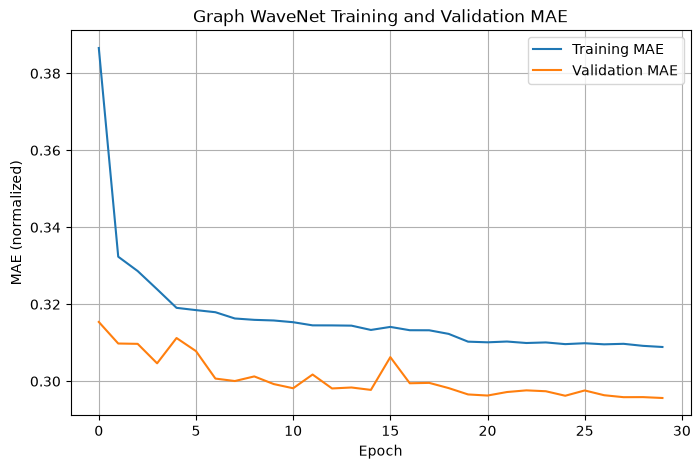

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history["train"], label="Training MAE")
plt.plot(history["validation"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (normalized)")
plt.title("Graph WaveNet Training and Validation MAE")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Load trained model
model.load_state_dict(
    torch.load("checkpoints/gwnet_mmtd_best.pth", map_location=device, weights_only=True)
)
# eval mode
model.eval()

# Load normalization values
scaler = np.load(Path(OUTPUT_DIR) / "scaler_v3.npz")

target_mean = torch.tensor(
    scaler["mean"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)

target_std = torch.tensor(
    scaler["std"][:, TARGET_FEATURE], dtype=torch.float32, device=device
).view(1, 1, MAX_NODES)


# Test the model

In [ ]:
all_predictions = []
all_targets = []
all_baseline = []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        y = y.to(device)

        model_input = x.permute(0, 3, 2, 1).contiguous()
        output = model(model_input)
        prediction = output[:, :, :, HORIZON_IDX]

        # Persistence: last observed congestion in input window
        baseline = x[:, -1, :, TARGET_FEATURE].unsqueeze(1)

        all_predictions.append(prediction)
        all_targets.append(y)
        all_baseline.append(baseline)

predictions = torch.cat(all_predictions, dim=0)
targets = torch.cat(all_targets, dim=0)
baseline = torch.cat(all_baseline, dim=0)

# Normalized MAE
norm_model_mae = torch.mean(torch.abs(predictions - targets)).item()
norm_baseline_mae = torch.mean(torch.abs(baseline - targets)).item()

# Real-unit MAE
predictions_real = predictions * target_std + target_mean
targets_real = targets * target_std + target_mean
baseline_real = baseline * target_std + target_mean

model_mae = torch.mean(torch.abs(predictions_real - targets_real)).item()
baseline_mae = torch.mean(torch.abs(baseline_real - targets_real)).item()

print(f"Normalized Graph WaveNet Test MAE: {norm_model_mae:.5f}")
print(f"Normalized Persistence Test MAE:   {norm_baseline_mae:.5f}")
print("-" * 45)
print(f"Real-Unit Graph WaveNet Test MAE:  {model_mae:.5f}")
print(f"Real-Unit Persistence Test MAE:    {baseline_mae:.5f}")

Normalized Graph WaveNet Test MAE: 0.34516
Normalized Persistence Test MAE:   0.44000
---------------------------------------------
Real-Unit Graph WaveNet Test MAE:  1.90334
Real-Unit Persistence Test MAE:    2.40712


In [ ]:
# save results

results = {
    "nodes": MAX_NODES,
    "input_features": features,
    "target": features[TARGET_FEATURE],
    "sequence_length": SEQ_LEN,
    "prediction_interval": "15 minutes",
    "graph_wavenet_test_mae": model_mae,
    "persistence_test_mae": baseline_mae,
    "best_validation_loss": best_val_loss
}

# Create results directory automatically
RESULTS_DIR = Path.cwd() / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save JSON file
RESULTS_PATH = RESULTS_DIR / "gwnet_mmtd_results.json"

with open(RESULTS_PATH, "w") as f:
    json.dump(results, f, indent=4)

print(json.dumps(results, indent=4))
print("\nResults saved to:", RESULTS_PATH)

{
    "nodes": 2780,
    "input_features": [
        "volume",
        "occ",
        "conges_levl",
        "temperature_2m_C",
        "relative_humidity_2m_percent",
        "precipitation_mm",
        "road_Oneway",
        "road_RoadType",
        "road_Length",
        "road_Tunnel",
        "road_SpeedLimit",
        "road_InDegree",
        "road_OutDegree",
        "road_BetweennessCentrality",
        "road_ClosenessCentrality",
        "road_Heading",
        "road_Curviness",
        "road_CurvatureRatio",
        "road_x",
        "road_y",
        "road_poi_count",
        "road_poi_density",
        "road_work_count",
        "road_work_density",
        "road_residential_count",
        "road_residential_density",
        "road_education_count",
        "road_education_density",
        "road_medical_count",
        "road_medical_density",
        "road_food_count",
        "road_food_density",
        "road_shopping_count",
        "road_shopping_density",
        "roa

# Input and Results illustrated for one node

In [ ]:
sample_idx = 0
node_id = 0

model.eval()
x, y = test_loader.dataset[sample_idx]
x = x.unsqueeze(0).to(device)
y = y.unsqueeze(0).to(device)

model_input = x.permute(0, 3, 2, 1).contiguous()

with torch.no_grad():
    output = model(model_input)
    prediction = output[:, :, :, HORIZON_IDX]

prediction_real = prediction * target_std + target_mean
actual_real = y * target_std + target_mean

feature_values = x[0, :, node_id, :].cpu().numpy()
feature_df = pd.DataFrame(feature_values, columns=features)
feature_df.insert(0, "Timestep", range(1, SEQ_LEN + 1))

print(f"\nInput feature values for Node {node_id} (Sample {sample_idx}):")
display(feature_df)

results_df = pd.DataFrame({
    "Node": range(MAX_NODES),
    "Predicted Congestion": prediction_real[0, 0].cpu().numpy(),
    "Actual Congestion": actual_real[0, 0].cpu().numpy(),
})
results_df["Abs Error"] = (
    results_df["Predicted Congestion"] - results_df["Actual Congestion"]
).abs()

display(results_df)


Input feature values for Node 0 (Sample 0):


,Timestep,volume,occ,conges_levl,temperature_2m_C,relative_humidity_2m_percent,precipitation_mm,road_Oneway,road_RoadType,road_Length,...,road_other_density,road_work_residential_ratio,road_commercial_residential_ratio,road_entertainment_residential_ratio,road_poi_diversity,road_poi_mix_entropy,road_weekday_dominance,road_peak_hour_impact,road_all_day_impact,road_weekend_impact
0,1,-0.214051,-0.822761,-0.219130,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
1,2,-0.622365,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
2,3,-0.156354,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
3,4,-0.560230,-0.822761,-0.353979,0.996532,-0.692347,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
4,5,-0.156354,-0.822761,-0.488828,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
5,6,0.127690,0.170028,0.185417,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
6,7,-0.107534,0.170028,0.050568,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
7,8,-0.009894,0.170028,-0.084281,1.032475,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
8,9,0.034488,0.170028,0.050568,0.960588,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335
9,10,0.132128,-0.822761,-0.084281,0.960588,-0.834389,0.0,0.880468,-1.476284,1.763166,...,-0.65582,-0.131217,0.226332,0.008566,-0.299485,0.101557,-0.10429,-0.452196,-0.806761,0.799335


,Node,Predicted Congestion,Actual Congestion,Abs Error
0,0,13.999434,15.0,1.000566
1,1,8.038300,10.0,1.961700
2,2,18.084488,17.0,1.084488
3,3,0.873194,0.0,0.873194
4,4,10.770977,11.0,0.229023
...,...,...,...,...
2775,2775,7.200741,8.0,0.799259
2776,2776,9.131179,11.0,1.868821
2777,2777,9.155187,11.0,1.844813
2778,2778,15.467270,17.0,1.532730


# TODO

* Convert congestion to travel time with road length
* Integrate algo with GNN